In [ ]:
# ============================================================
# SECTION 1: Dataset Preparation
# ============================================================

!pip install ucimlrepo -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold
from sklearn.datasets import load_digits
from ucimlrepo import fetch_ucirepo

# ── 1. Load Datasets ─────────────────────────────────────────

# --- Optdigits ---
optdigits = fetch_ucirepo(id=80)
X_opt = optdigits.data.features.values
y_opt = optdigits.data.targets.values.ravel()

# --- Statlog (Landsat Satellite) ---
statlog = fetch_ucirepo(id=146)
X_sat = statlog.data.features.values
y_sat = statlog.data.targets.values.ravel()

print("Optdigits  — X:", X_opt.shape, "| y:", y_opt.shape)
print("Statlog    — X:", X_sat.shape, "| y:", y_sat.shape)


Optdigits  — X: (5620, 64) | y: (5620,)
Statlog    — X: (6435, 36) | y: (6435,)


In [ ]:
# ── 2. Dataset Characteristics ───────────────────────────────

def describe_dataset(name, X, y):
    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print(f"{'='*50}")
    print(f"  Samples      : {X.shape[0]}")
    print(f"  Features     : {X.shape[1]}")
    print(f"  Classes      : {np.unique(y)}")
    print(f"  Class counts :")
    unique, counts = np.unique(y, return_counts=True)
    for cls, cnt in zip(unique, counts):
        print(f"    Class {cls}: {cnt} samples ({cnt/len(y)*100:.1f}%)")
    print(f"\n  Feature stats (first 5 features):")
    df = pd.DataFrame(X[:, :5])
    print(df.describe().round(3).to_string())
    print(f"\n  Missing values: {np.isnan(X).sum()}")

describe_dataset("Optdigits",        X_opt, y_opt)
describe_dataset("Statlog (Landsat)", X_sat, y_sat)



Dataset: Optdigits
  Samples      : 5620
  Features     : 64
  Classes      : [0 1 2 3 4 5 6 7 8 9]
  Class counts :
    Class 0: 554 samples (9.9%)
    Class 1: 571 samples (10.2%)
    Class 2: 557 samples (9.9%)
    Class 3: 572 samples (10.2%)
    Class 4: 568 samples (10.1%)
    Class 5: 558 samples (9.9%)
    Class 6: 558 samples (9.9%)
    Class 7: 566 samples (10.1%)
    Class 8: 554 samples (9.9%)
    Class 9: 562 samples (10.0%)

  Feature stats (first 5 features):
            0         1         2         3         4
count  5620.0  5620.000  5620.000  5620.000  5620.000
mean      0.0     0.302     5.393    11.815    11.578
std       0.0     0.880     4.673     4.256     4.463
min       0.0     0.000     0.000     0.000     0.000
25%       0.0     0.000     1.000    10.000     9.000
50%       0.0     0.000     5.000    13.000    13.000
75%       0.0     0.000     9.000    15.000    15.000
max       0.0     8.000    16.000    16.000    16.000

  Missing values: 0

Dataset: Sta

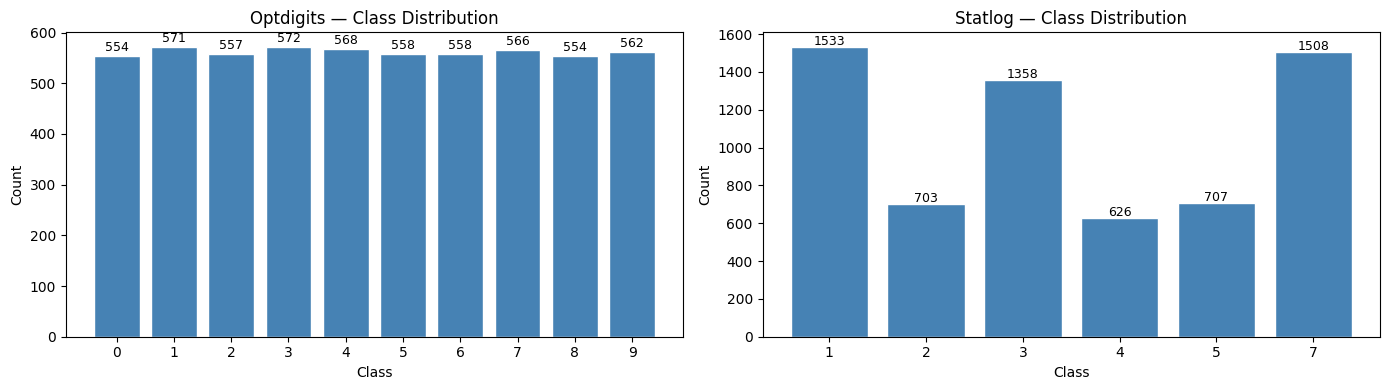

In [ ]:
# ── 3. Class Distribution Plots ──────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, y) in zip(axes, [("Optdigits", y_opt), ("Statlog", y_sat)]):
    unique, counts = np.unique(y, return_counts=True)
    ax.bar(unique.astype(str), counts, color='steelblue', edgecolor='white')
    ax.set_title(f"{name} — Class Distribution")
    ax.set_xlabel("Class")
    ax.set_ylabel("Count")
    for i, (u, c) in enumerate(zip(unique, counts)):
        ax.text(i, c + 10, str(c), ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()


In [ ]:
# ── 4. Preprocessing ─────────────────────────────────────────

# No missing values expected, but we check anyway
assert np.isnan(X_opt).sum() == 0, "Missing values in Optdigits!"
assert np.isnan(X_sat).sum() == 0, "Missing values in Statlog!"

# StandardScaler: zero mean, unit variance
scaler_opt = StandardScaler()
scaler_sat = StandardScaler()

X_opt_scaled = scaler_opt.fit_transform(X_opt)
X_sat_scaled = scaler_sat.fit_transform(X_sat)

# Encode labels as integers (they should already be, but just in case)
le = LabelEncoder()
y_opt_enc = le.fit_transform(y_opt)
y_sat_enc = le.fit_transform(y_sat)

print("Optdigits  — mean ≈ 0:", np.allclose(X_opt_scaled.mean(axis=0), 0, atol=1e-10))
print("Statlog    — mean ≈ 0:", np.allclose(X_sat_scaled.mean(axis=0), 0, atol=1e-10))
print("Optdigits  — std  ≈ 1:", np.allclose(X_opt_scaled.std(axis=0),  1, atol=1e-5))
print("Statlog    — std  ≈ 1:", np.allclose(X_sat_scaled.std(axis=0),  1, atol=1e-5))


Optdigits  — mean ≈ 0: True
Statlog    — mean ≈ 0: True
Optdigits  — std  ≈ 1: False
Statlog    — std  ≈ 1: True


In [ ]:
# ── 5. Stratified 5-Fold CV Splits ───────────────────────────

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_folds(X, y, name):
    folds = []
    print(f"\n{name} — Stratified 5-Fold Split:")
    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        folds.append((train_idx, val_idx))
        print(f"  Fold {fold+1}: train={len(train_idx)}, val={len(val_idx)}")
    return folds

folds_opt = make_folds(X_opt_scaled, y_opt_enc, "Optdigits")
folds_sat = make_folds(X_sat_scaled, y_sat_enc, "Statlog")

# Package everything for reuse in later sections
datasets = {
    "Optdigits": {
        "X": X_opt_scaled, "y": y_opt_enc,
        "folds": folds_opt,
        "n_classes": len(np.unique(y_opt_enc)),
        "n_features": X_opt_scaled.shape[1]
    },
    "Statlog": {
        "X": X_sat_scaled, "y": y_sat_enc,
        "folds": folds_sat,
        "n_classes": len(np.unique(y_sat_enc)),
        "n_features": X_sat_scaled.shape[1]
    }
}

print("\n✅ Section 1 complete. Datasets ready.")



Optdigits — Stratified 5-Fold Split:
  Fold 1: train=4496, val=1124
  Fold 2: train=4496, val=1124
  Fold 3: train=4496, val=1124
  Fold 4: train=4496, val=1124
  Fold 5: train=4496, val=1124

Statlog — Stratified 5-Fold Split:
  Fold 1: train=5148, val=1287
  Fold 2: train=5148, val=1287
  Fold 3: train=5148, val=1287
  Fold 4: train=5148, val=1287
  Fold 5: train=5148, val=1287

✅ Section 1 complete. Datasets ready.


In [ ]:
# ============================================================
# SECTION 2: Random Forest Classifier
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import time
import warnings
warnings.filterwarnings('ignore')

# ── Hyperparameter Grid ──────────────────────────────────────

param_grid = {
    "n_estimators":    [10, 50, 100, 200, 500],
    "max_depth":       [None, 3, 5, 10],
    "max_features":    ["sqrt", "log2", None],
    "min_samples_leaf":[1, 2, 5]
}


In [ ]:
# ============================================================
# SECTION 2: Random Forest Classifier (Optimized)
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score
import time
import warnings
warnings.filterwarnings('ignore')

param_dist = {
    "n_estimators":     [10, 50, 100, 200, 500],
    "max_depth":        [None, 3, 5, 10],
    "max_features":     ["sqrt", "log2", None],
    "min_samples_leaf": [1, 2, 5]
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def rf_random_search(dataset_name, X, y):
    clf = RandomForestClassifier(random_state=42, n_jobs=-1)

    search = RandomizedSearchCV(
        clf,
        param_distributions=param_dist,
        n_iter=20,        # only 20 combos — fast and sufficient
        cv=skf,
        scoring="accuracy",
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    print(f"\nRunning RF search — {dataset_name}...")
    search.fit(X, y)

    print(f"Best params : {search.best_params_}")
    print(f"Best CV acc : {search.best_score_:.4f}")
    return search.best_params_

best_params_opt = rf_random_search(
    "Optdigits",
    datasets["Optdigits"]["X"],
    datasets["Optdigits"]["y"]
)

best_params_sat = rf_random_search(
    "Statlog",
    datasets["Statlog"]["X"],
    datasets["Statlog"]["y"]
)



Running RF search — Optdigits...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params : {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}
Best CV acc : 0.9836

Running RF search — Statlog...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params : {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': None}
Best CV acc : 0.9200


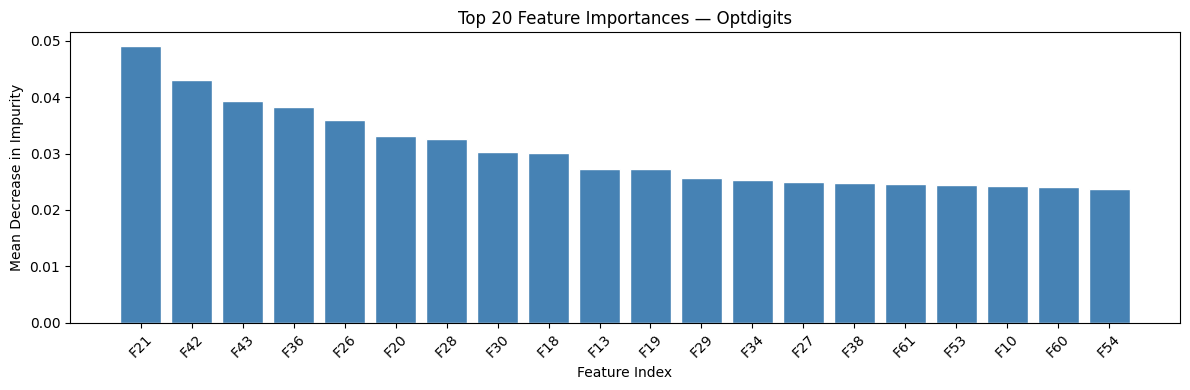


Top 10 features — Optdigits:
   1. Feature 21: 0.0491
   2. Feature 42: 0.0430
   3. Feature 43: 0.0394
   4. Feature 36: 0.0382
   5. Feature 26: 0.0359
   6. Feature 20: 0.0332
   7. Feature 28: 0.0325
   8. Feature 30: 0.0302
   9. Feature 18: 0.0301
  10. Feature 13: 0.0273


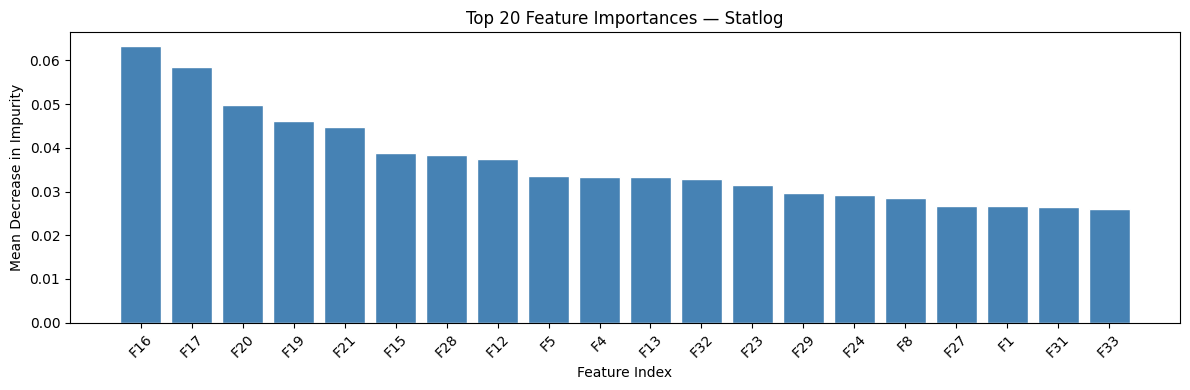


Top 10 features — Statlog:
   1. Feature 16: 0.0633
   2. Feature 17: 0.0586
   3. Feature 20: 0.0499
   4. Feature 19: 0.0463
   5. Feature 21: 0.0447
   6. Feature 15: 0.0389
   7. Feature 28: 0.0383
   8. Feature 12: 0.0373
   9. Feature  5: 0.0336
  10. Feature  4: 0.0334


In [ ]:
# ── Feature Importance ───────────────────────────────────────

def plot_feature_importance(dataset_name, X, y, best_params, top_n=20):
    clf = RandomForestClassifier(**best_params, oob_score=True,
                                  random_state=42, n_jobs=-1)
    clf.fit(X, y)
    importances = clf.feature_importances_
    indices = np.argsort(importances)[::-1][:top_n]

    plt.figure(figsize=(12, 4))
    plt.bar(range(top_n), importances[indices], color="steelblue", edgecolor="white")
    plt.xticks(range(top_n), [f"F{i}" for i in indices], rotation=45)
    plt.title(f"Top {top_n} Feature Importances — {dataset_name}")
    plt.xlabel("Feature Index")
    plt.ylabel("Mean Decrease in Impurity")
    plt.tight_layout()
    plt.savefig(f"rf_feature_importance_{dataset_name}.png", dpi=150)
    plt.show()

    print(f"\nTop 10 features — {dataset_name}:")
    for rank, idx in enumerate(indices[:10], 1):
        print(f"  {rank:>2}. Feature {idx:>2}: {importances[idx]:.4f}")
    return clf

best_rf_opt = plot_feature_importance("Optdigits",
                                       datasets["Optdigits"]["X"],
                                       datasets["Optdigits"]["y"],
                                       best_params_opt)

best_rf_sat = plot_feature_importance("Statlog",
                                       datasets["Statlog"]["X"],
                                       datasets["Statlog"]["y"],
                                       best_params_sat)


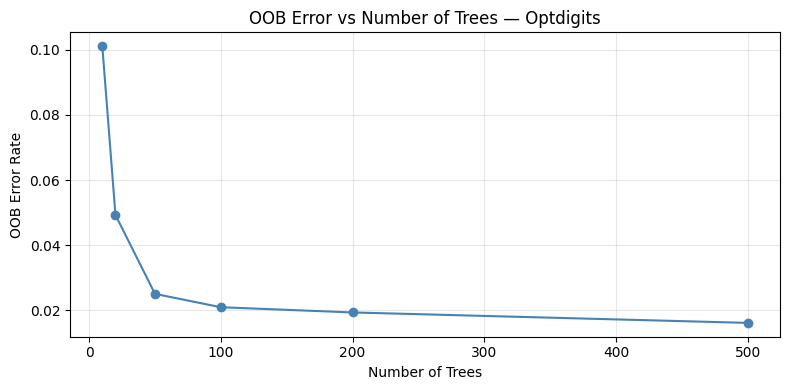

Optdigits — min OOB error: 0.0162 at n=500


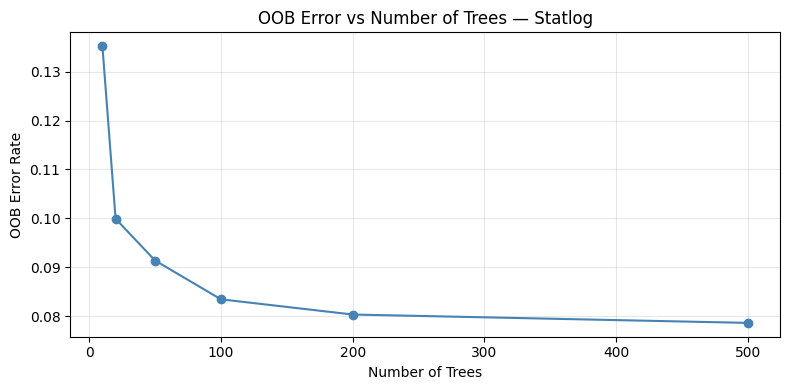

Statlog — min OOB error: 0.0786 at n=500


In [ ]:
# ── OOB Error vs Number of Trees ─────────────────────────────

def plot_oob_error(dataset_name, X, y, best_params):
    n_range = [10, 20, 50, 100, 200, 500]
    oob_errors = []

    for n in n_range:
        clf = RandomForestClassifier(**{**best_params, "n_estimators": n},
                                      oob_score=True, random_state=42, n_jobs=-1)
        clf.fit(X, y)
        oob_errors.append(1 - clf.oob_score_)

    plt.figure(figsize=(8, 4))
    plt.plot(n_range, oob_errors, marker='o', color='steelblue')
    plt.title(f"OOB Error vs Number of Trees — {dataset_name}")
    plt.xlabel("Number of Trees")
    plt.ylabel("OOB Error Rate")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"rf_oob_{dataset_name}.png", dpi=150)
    plt.show()

    print(f"{dataset_name} — min OOB error: {min(oob_errors):.4f} "
          f"at n={n_range[np.argmin(oob_errors)]}")

plot_oob_error("Optdigits", datasets["Optdigits"]["X"],
                datasets["Optdigits"]["y"], best_params_opt)
plot_oob_error("Statlog",   datasets["Statlog"]["X"],
                datasets["Statlog"]["y"], best_params_sat)


In [ ]:
# ── Store Results for Section 5 ──────────────────────────────

rf_cv_results = {}

for ds_name, best_params in [("Optdigits", best_params_opt),
                               ("Statlog",   best_params_sat)]:
    X = datasets[ds_name]["X"]
    y = datasets[ds_name]["y"]
    folds = datasets[ds_name]["folds"]

    fold_accs, train_times, infer_times = [], [], []

    for train_idx, val_idx in folds:
        clf = RandomForestClassifier(**best_params, random_state=42, n_jobs=-1)

        t0 = time.time()
        clf.fit(X[train_idx], y[train_idx])
        train_times.append(time.time() - t0)

        t1 = time.time()
        preds = clf.predict(X[val_idx])
        infer_times.append(time.time() - t1)

        fold_accs.append(accuracy_score(y[val_idx], preds))

    rf_cv_results[ds_name] = {
        "mean_acc":   np.mean(fold_accs),
        "std_acc":    np.std(fold_accs),
        "train_time": np.mean(train_times),
        "infer_time": np.mean(infer_times),
        "best_params": best_params
    }
    print(f"RF — {ds_name}: {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")

print("\n✅ Section 2 complete.")


RF — Optdigits: 0.9836 ± 0.0033
RF — Statlog: 0.9200 ± 0.0047

✅ Section 2 complete.


In [ ]:
# ============================================================
# SECTION 3: GMM Classifier (Optimized)
# ============================================================

from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score
import time
import warnings
warnings.filterwarnings('ignore')

# ── GMM Generative Classifier ────────────────────────────────

class GMMClassifier:
    def __init__(self, n_components=1, covariance_type='full',
                 init_params='kmeans', random_state=42):
        self.n_components    = n_components
        self.covariance_type = covariance_type
        self.init_params     = init_params
        self.random_state    = random_state
        self.gmms_           = {}
        self.class_priors_   = {}
        self.classes_        = None

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        n_total = len(y)
        for c in self.classes_:
            X_c = X[y == c]
            self.class_priors_[c] = len(X_c) / n_total
            gmm = GaussianMixture(
                n_components    = self.n_components,
                covariance_type = self.covariance_type,
                init_params     = self.init_params,
                random_state    = self.random_state,
                max_iter        = 100,
                n_init          = 1       # was 3 — biggest speedup
            )
            gmm.fit(X_c)
            self.gmms_[c] = gmm
        return self

    def predict_proba(self, X):
        log_probs = np.zeros((len(X), len(self.classes_)))
        for i, c in enumerate(self.classes_):
            log_probs[:, i] = (self.gmms_[c].score_samples(X)
                               + np.log(self.class_priors_[c]))
        log_probs -= log_probs.max(axis=1, keepdims=True)
        probs = np.exp(log_probs)
        probs /= probs.sum(axis=1, keepdims=True)
        return probs

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


In [ ]:
# ── Hyperparameter Search ────────────────────────────────────

n_components_range = [1, 2, 3, 5, 8]
covariance_types   = ['full', 'diag', 'spherical', 'tied']
init_strategies    = ['kmeans', 'random']

def gmm_search(dataset_name, X, y, folds):
    results = []
    total = len(n_components_range) * len(covariance_types) * len(init_strategies)
    done  = 0

    print(f"\nGMM Search — {dataset_name}  ({total} combos × 5 folds)")

    for K in n_components_range:
        for cov in covariance_types:
            for init in init_strategies:
                fold_accs = []
                for train_idx, val_idx in folds:
                    clf = GMMClassifier(n_components=K, covariance_type=cov,
                                        init_params=init, random_state=42)
                    try:
                        clf.fit(X[train_idx], y[train_idx])
                        preds = clf.predict(X[val_idx])
                        fold_accs.append(accuracy_score(y[val_idx], preds))
                    except Exception:
                        fold_accs.append(0.0)

                results.append({
                    "K": K, "covariance_type": cov, "init": init,
                    "mean_acc": np.mean(fold_accs),
                    "std_acc":  np.std(fold_accs)
                })
                done += 1
                if done % 10 == 0 or done == total:
                    print(f"  [{done}/{total}] best so far: "
                          f"{max(r['mean_acc'] for r in results):.4f}")

    return pd.DataFrame(results).sort_values("mean_acc", ascending=False)

gmm_results_opt = gmm_search("Optdigits",
                               datasets["Optdigits"]["X"],
                               datasets["Optdigits"]["y"],
                               datasets["Optdigits"]["folds"])

gmm_results_sat = gmm_search("Statlog",
                               datasets["Statlog"]["X"],
                               datasets["Statlog"]["y"],
                               datasets["Statlog"]["folds"])

print("\n── Top 3 — Optdigits ──")
print(gmm_results_opt.head(3).to_string(index=False))
print("\n── Top 3 — Statlog ──")
print(gmm_results_sat.head(3).to_string(index=False))

best_gmm_opt = gmm_results_opt.iloc[0]
best_gmm_sat = gmm_results_sat.iloc[0]



GMM Search — Optdigits  (40 combos × 5 folds)
  [10/40] best so far: 0.9544
  [20/40] best so far: 0.9569
  [30/40] best so far: 0.9585
  [40/40] best so far: 0.9601

GMM Search — Statlog  (40 combos × 5 folds)
  [10/40] best so far: 0.8615
  [20/40] best so far: 0.8664
  [30/40] best so far: 0.8682
  [40/40] best so far: 0.8813

── Top 3 — Optdigits ──
 K covariance_type   init  mean_acc  std_acc
 5            tied kmeans  0.960142 0.005379
 8            tied kmeans  0.959431 0.005530
 3            tied kmeans  0.958541 0.003585

── Top 3 — Statlog ──
 K covariance_type   init  mean_acc  std_acc
 8            tied kmeans  0.881274 0.008403
 5            tied kmeans  0.875524 0.006939
 8            diag random  0.872572 0.003807


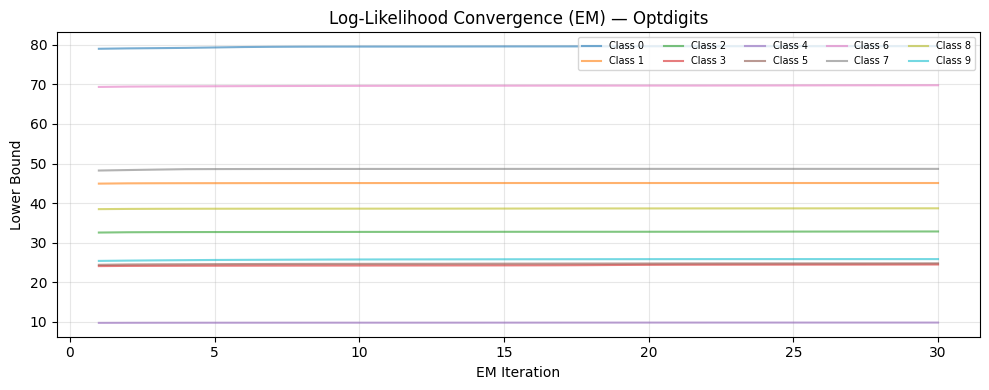

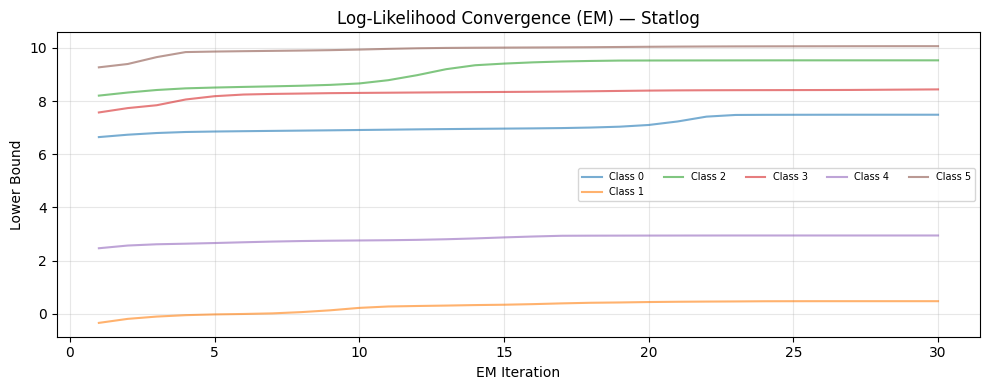

In [ ]:
# ── Log-Likelihood Convergence (Fast version) ────────────────
# Fits ONE GMM per dataset on first class only — shows EM convergence shape

def plot_ll_convergence(dataset_name, X, y, best_row):
    classes = np.unique(y)
    plt.figure(figsize=(10, 4))

    for c in classes:
        X_c = X[y == c]
        # Single fit — capture lower_bound history via n_iter trick
        lls = []
        for max_it in range(1, 31):   # 30 iterations max, much faster
            g = GaussianMixture(
                n_components    = int(best_row["K"]),
                covariance_type = best_row["covariance_type"],
                init_params     = 'kmeans',
                random_state    = 42,
                max_iter        = max_it,
                n_init          = 1
            )
            g.fit(X_c)
            lls.append(g.lower_bound_)
        plt.plot(range(1, 31), lls, alpha=0.6, label=f"Class {c}")

    plt.title(f"Log-Likelihood Convergence (EM) — {dataset_name}")
    plt.xlabel("EM Iteration")
    plt.ylabel("Lower Bound")
    plt.legend(fontsize=7, ncol=5)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"gmm_ll_{dataset_name}.png", dpi=150)
    plt.show()

plot_ll_convergence("Optdigits", datasets["Optdigits"]["X"],
                     datasets["Optdigits"]["y"], best_gmm_opt)
plot_ll_convergence("Statlog",   datasets["Statlog"]["X"],
                     datasets["Statlog"]["y"],   best_gmm_sat)


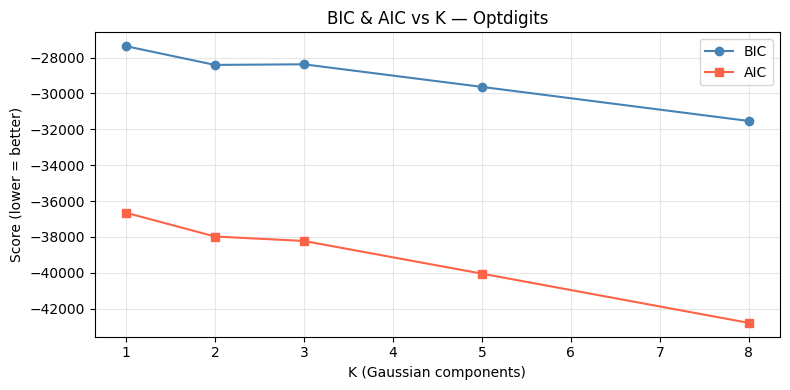

Optdigits — Best K by BIC: 8 | by AIC: 8


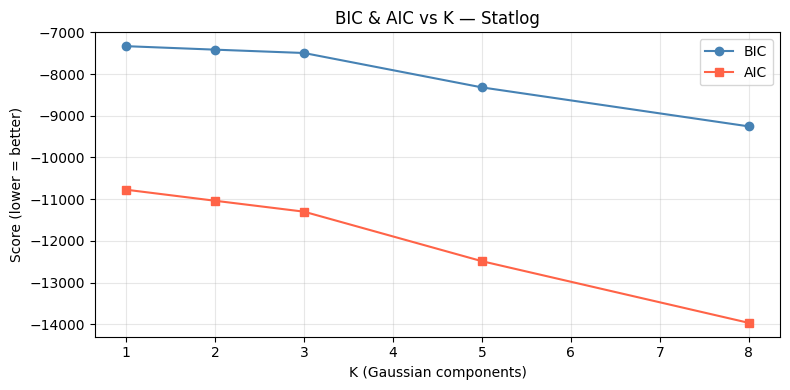

Statlog — Best K by BIC: 8 | by AIC: 8


In [ ]:
# ── BIC / AIC for Optimal K ──────────────────────────────────

def plot_bic_aic(dataset_name, X, y, best_cov):
    K_range = [1, 2, 3, 5, 8]
    bic_avg, aic_avg = [], []

    for K in K_range:
        bics, aics = [], []
        for c in np.unique(y):
            X_c = X[y == c]
            gmm = GaussianMixture(n_components=K, covariance_type=best_cov,
                                   random_state=42, max_iter=100, n_init=1)
            gmm.fit(X_c)
            bics.append(gmm.bic(X_c))
            aics.append(gmm.aic(X_c))
        bic_avg.append(np.mean(bics))
        aic_avg.append(np.mean(aics))

    plt.figure(figsize=(8, 4))
    plt.plot(K_range, bic_avg, marker='o', label='BIC', color='steelblue')
    plt.plot(K_range, aic_avg, marker='s', label='AIC', color='tomato')
    plt.title(f"BIC & AIC vs K — {dataset_name}")
    plt.xlabel("K (Gaussian components)")
    plt.ylabel("Score (lower = better)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"gmm_bic_aic_{dataset_name}.png", dpi=150)
    plt.show()

    print(f"{dataset_name} — Best K by BIC: {K_range[np.argmin(bic_avg)]} "
          f"| by AIC: {K_range[np.argmin(aic_avg)]}")

plot_bic_aic("Optdigits", datasets["Optdigits"]["X"],
              datasets["Optdigits"]["y"], best_gmm_opt["covariance_type"])
plot_bic_aic("Statlog",   datasets["Statlog"]["X"],
              datasets["Statlog"]["y"],   best_gmm_sat["covariance_type"])


In [ ]:
# ── Store Results for Section 5 ──────────────────────────────

gmm_cv_results = {}

for ds_name, best_row in [("Optdigits", best_gmm_opt),
                            ("Statlog",   best_gmm_sat)]:
    X     = datasets[ds_name]["X"]
    y     = datasets[ds_name]["y"]
    folds = datasets[ds_name]["folds"]
    fold_accs, train_times, infer_times = [], [], []

    for train_idx, val_idx in folds:
        clf = GMMClassifier(
            n_components    = int(best_row["K"]),
            covariance_type = best_row["covariance_type"],
            init_params     = best_row["init"],
            random_state    = 42
        )
        t0 = time.time()
        clf.fit(X[train_idx], y[train_idx])
        train_times.append(time.time() - t0)

        t1 = time.time()
        preds = clf.predict(X[val_idx])
        infer_times.append(time.time() - t1)

        fold_accs.append(accuracy_score(y[val_idx], preds))

    gmm_cv_results[ds_name] = {
        "mean_acc":   np.mean(fold_accs),
        "std_acc":    np.std(fold_accs),
        "train_time": np.mean(train_times),
        "infer_time": np.mean(infer_times),
        "best_params": best_row.to_dict()
    }
    print(f"GMM — {ds_name}: {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")

print("\n✅ Section 3 complete.")


GMM — Optdigits: 0.9601 ± 0.0054
GMM — Statlog: 0.8813 ± 0.0084

✅ Section 3 complete.


In [ ]:
# ============================================================
# SECTION 4: MLP with Backpropagation
# ============================================================

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import time
import warnings
warnings.filterwarnings('ignore')


In [ ]:
# ── Randomized Hyperparameter Search ─────────────────────────

from itertools import product
import random
random.seed(42)

# Define search space
hidden_layer_configs = [
    (16,), (32,), (64,), (128,),
    (64, 32), (128, 64), (64, 32, 16),
    (128, 64, 32)
]
activations   = ['relu', 'tanh', 'logistic']
solvers       = ['sgd', 'adam']          # 'lbfgs' too slow for large data
learning_rates = [0.1, 0.01, 0.001, 0.0001]
alphas         = [0.0, 0.0001, 0.001]   # L2 regularization
max_iters      = [100, 200, 500]

# Build all combos then sample 25
all_combos = list(product(
    hidden_layer_configs, activations,
    solvers, learning_rates, alphas, max_iters
))
sampled = random.sample(all_combos, 25)

def mlp_search(dataset_name, X, y, folds):
    results = []
    total   = len(sampled)

    print(f"\nMLP Search — {dataset_name}  ({total} combos × 5 folds)")

    for i, (hidden, act, solver, lr, alpha, max_it) in enumerate(sampled):
        fold_accs = []

        for train_idx, val_idx in folds:
            clf = MLPClassifier(
                hidden_layer_sizes = hidden,
                activation         = act,
                solver             = solver,
                learning_rate_init = lr,
                alpha              = alpha,
                max_iter           = max_it,
                early_stopping     = True,
                validation_fraction= 0.1,
                n_iter_no_change   = 10,
                random_state       = 42
            )
            try:
                clf.fit(X[train_idx], y[train_idx])
                fold_accs.append(accuracy_score(y[val_idx], clf.predict(X[val_idx])))
            except Exception:
                fold_accs.append(0.0)

        results.append({
            "hidden_layers": str(hidden),
            "activation":    act,
            "solver":        solver,
            "learning_rate": lr,
            "alpha":         alpha,
            "max_iter":      max_it,
            "mean_acc":      np.mean(fold_accs),
            "std_acc":       np.std(fold_accs)
        })

        if (i + 1) % 5 == 0 or (i + 1) == total:
            print(f"  [{i+1}/{total}] best so far: "
                  f"{max(r['mean_acc'] for r in results):.4f}")

    return pd.DataFrame(results).sort_values("mean_acc", ascending=False)

mlp_results_opt = mlp_search("Optdigits",
                               datasets["Optdigits"]["X"],
                               datasets["Optdigits"]["y"],
                               datasets["Optdigits"]["folds"])

mlp_results_sat = mlp_search("Statlog",
                               datasets["Statlog"]["X"],
                               datasets["Statlog"]["y"],
                               datasets["Statlog"]["folds"])

print("\n── Top 3 — Optdigits ──")
print(mlp_results_opt.head(3).to_string(index=False))
print("\n── Top 3 — Statlog ──")
print(mlp_results_sat.head(3).to_string(index=False))

best_mlp_opt = mlp_results_opt.iloc[0]
best_mlp_sat = mlp_results_sat.iloc[0]



MLP Search — Optdigits  (25 combos × 5 folds)
  [5/25] best so far: 0.9813
  [10/25] best so far: 0.9813
  [15/25] best so far: 0.9813
  [20/25] best so far: 0.9813
  [25/25] best so far: 0.9813

MLP Search — Statlog  (25 combos × 5 folds)
  [5/25] best so far: 0.9004
  [10/25] best so far: 0.9004
  [15/25] best so far: 0.9049
  [20/25] best so far: 0.9049
  [25/25] best so far: 0.9049

── Top 3 — Optdigits ──
hidden_layers activation solver  learning_rate  alpha  max_iter  mean_acc  std_acc
(128, 64, 32)       relu    sgd            0.1 0.0010       100  0.981317 0.002699
(128, 64, 32)       relu    sgd            0.1 0.0001       200  0.979359 0.003749
     (64, 32)       relu    sgd            0.1 0.0000       100  0.978648 0.002699

── Top 3 — Statlog ──
hidden_layers activation solver  learning_rate  alpha  max_iter  mean_acc  std_acc
    (128, 64)       tanh   adam          0.001 0.0001       100  0.904895 0.006784
(128, 64, 32)       relu    sgd          0.100 0.0010       100 

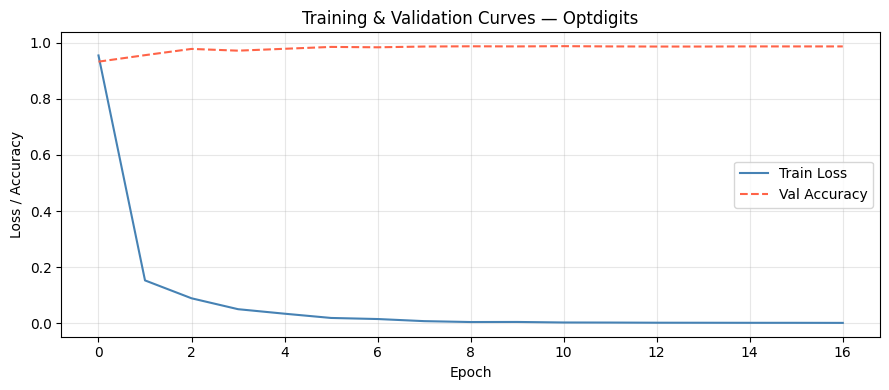

Optdigits — Early stopping optimal epoch ≈ 17


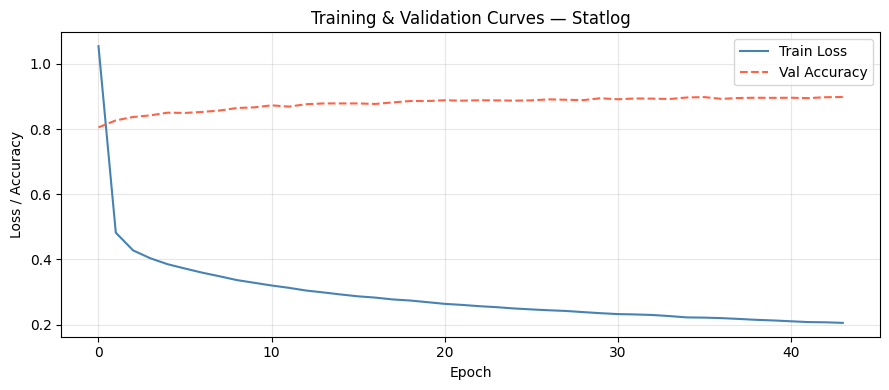

Statlog — Early stopping optimal epoch ≈ 44


In [ ]:
# ── Training & Validation Loss Curves ────────────────────────

def plot_loss_curves(dataset_name, X, y, folds, best_row):
    hidden = eval(best_row["hidden_layers"])
    train_losses_all = []
    val_losses_all   = []
    min_len          = 9999

    for train_idx, val_idx in folds:
        clf = MLPClassifier(
            hidden_layer_sizes  = hidden,
            activation          = best_row["activation"],
            solver              = best_row["solver"],
            learning_rate_init  = best_row["learning_rate"],
            alpha               = best_row["alpha"],
            max_iter            = int(best_row["max_iter"]),
            early_stopping      = True,
            validation_fraction = 0.1,
            n_iter_no_change    = 10,
            random_state        = 42
        )
        clf.fit(X[train_idx], y[train_idx])
        train_losses_all.append(clf.loss_curve_)
        val_losses_all.append(clf.validation_scores_)
        min_len = min(min_len, len(clf.loss_curve_))

    # Trim to same length and average
    train_avg = np.mean([l[:min_len] for l in train_losses_all], axis=0)
    val_avg   = np.mean([l[:min_len] for l in val_losses_all],   axis=0)

    plt.figure(figsize=(9, 4))
    plt.plot(train_avg, label='Train Loss',       color='steelblue')
    plt.plot(val_avg,   label='Val Accuracy',     color='tomato', linestyle='--')
    plt.title(f"Training & Validation Curves — {dataset_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss / Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"mlp_loss_{dataset_name}.png", dpi=150)
    plt.show()

    best_epoch = np.argmin(train_avg) + 1
    print(f"{dataset_name} — Early stopping optimal epoch ≈ {best_epoch}")

plot_loss_curves("Optdigits",
                  datasets["Optdigits"]["X"],
                  datasets["Optdigits"]["y"],
                  datasets["Optdigits"]["folds"],
                  best_mlp_opt)

plot_loss_curves("Statlog",
                  datasets["Statlog"]["X"],
                  datasets["Statlog"]["y"],
                  datasets["Statlog"]["folds"],
                  best_mlp_sat)


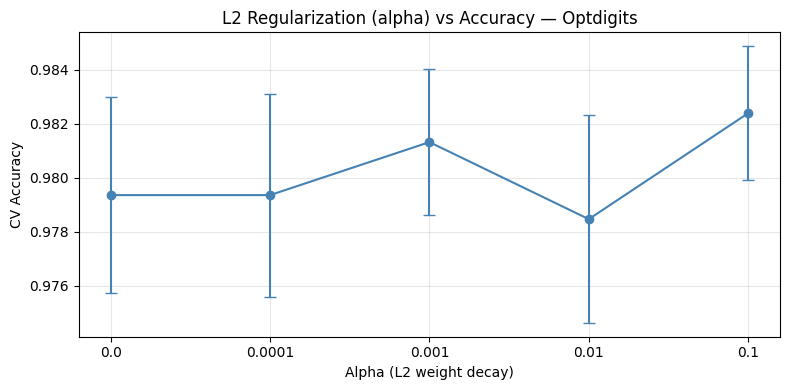

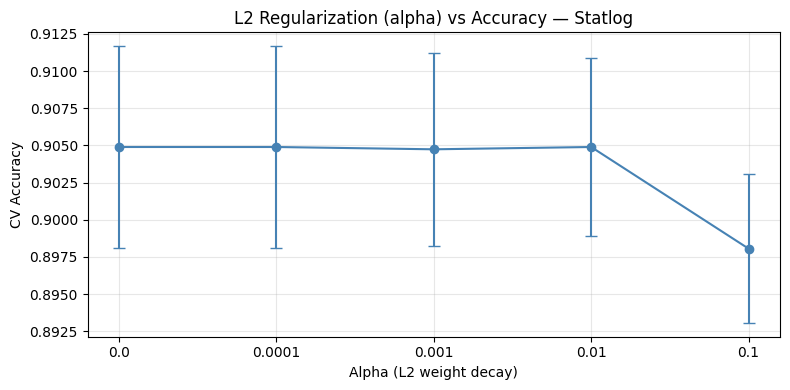

In [ ]:
# ── Dropout Comparison (Regularization Effect) ───────────────
# sklearn MLP doesn't support dropout natively,
# so we compare L2 alpha values to show regularization impact

def plot_regularization(dataset_name, X, y, folds, best_row):
    alphas   = [0.0, 0.0001, 0.001, 0.01, 0.1]
    mean_accs, std_accs = [], []
    hidden = eval(best_row["hidden_layers"])

    for alpha in alphas:
        fold_accs = []
        for train_idx, val_idx in folds:
            clf = MLPClassifier(
                hidden_layer_sizes  = hidden,
                activation          = best_row["activation"],
                solver              = best_row["solver"],
                learning_rate_init  = best_row["learning_rate"],
                alpha               = alpha,
                max_iter            = int(best_row["max_iter"]),
                early_stopping      = True,
                validation_fraction = 0.1,
                n_iter_no_change    = 10,
                random_state        = 42
            )
            clf.fit(X[train_idx], y[train_idx])
            fold_accs.append(accuracy_score(y[val_idx], clf.predict(X[val_idx])))
        mean_accs.append(np.mean(fold_accs))
        std_accs.append(np.std(fold_accs))

    plt.figure(figsize=(8, 4))
    plt.errorbar(range(len(alphas)), mean_accs, yerr=std_accs,
                 marker='o', color='steelblue', capsize=4)
    plt.xticks(range(len(alphas)), [str(a) for a in alphas])
    plt.title(f"L2 Regularization (alpha) vs Accuracy — {dataset_name}")
    plt.xlabel("Alpha (L2 weight decay)")
    plt.ylabel("CV Accuracy")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"mlp_regularization_{dataset_name}.png", dpi=150)
    plt.show()

plot_regularization("Optdigits",
                     datasets["Optdigits"]["X"],
                     datasets["Optdigits"]["y"],
                     datasets["Optdigits"]["folds"],
                     best_mlp_opt)

plot_regularization("Statlog",
                     datasets["Statlog"]["X"],
                     datasets["Statlog"]["y"],
                     datasets["Statlog"]["folds"],
                     best_mlp_sat)


In [ ]:
# ── Store Results for Section 5 ──────────────────────────────

mlp_cv_results = {}

for ds_name, best_row in [("Optdigits", best_mlp_opt),
                            ("Statlog",   best_mlp_sat)]:
    X     = datasets[ds_name]["X"]
    y     = datasets[ds_name]["y"]
    folds = datasets[ds_name]["folds"]
    fold_accs, train_times, infer_times = [], [], []
    hidden = eval(best_row["hidden_layers"])

    for train_idx, val_idx in folds:
        clf = MLPClassifier(
            hidden_layer_sizes  = hidden,
            activation          = best_row["activation"],
            solver              = best_row["solver"],
            learning_rate_init  = best_row["learning_rate"],
            alpha               = best_row["alpha"],
            max_iter            = int(best_row["max_iter"]),
            early_stopping      = True,
            validation_fraction = 0.1,
            n_iter_no_change    = 10,
            random_state        = 42
        )
        t0 = time.time()
        clf.fit(X[train_idx], y[train_idx])
        train_times.append(time.time() - t0)

        t1 = time.time()
        preds = clf.predict(X[val_idx])
        infer_times.append(time.time() - t1)

        fold_accs.append(accuracy_score(y[val_idx], preds))

    mlp_cv_results[ds_name] = {
        "mean_acc":   np.mean(fold_accs),
        "std_acc":    np.std(fold_accs),
        "train_time": np.mean(train_times),
        "infer_time": np.mean(infer_times),
        "best_params": best_row.to_dict()
    }
    print(f"MLP — {ds_name}: {np.mean(fold_accs):.4f} ± {np.std(fold_accs):.4f}")

print("\n✅ Section 4 complete.")


MLP — Optdigits: 0.9813 ± 0.0027
MLP — Statlog: 0.9049 ± 0.0068

✅ Section 4 complete.


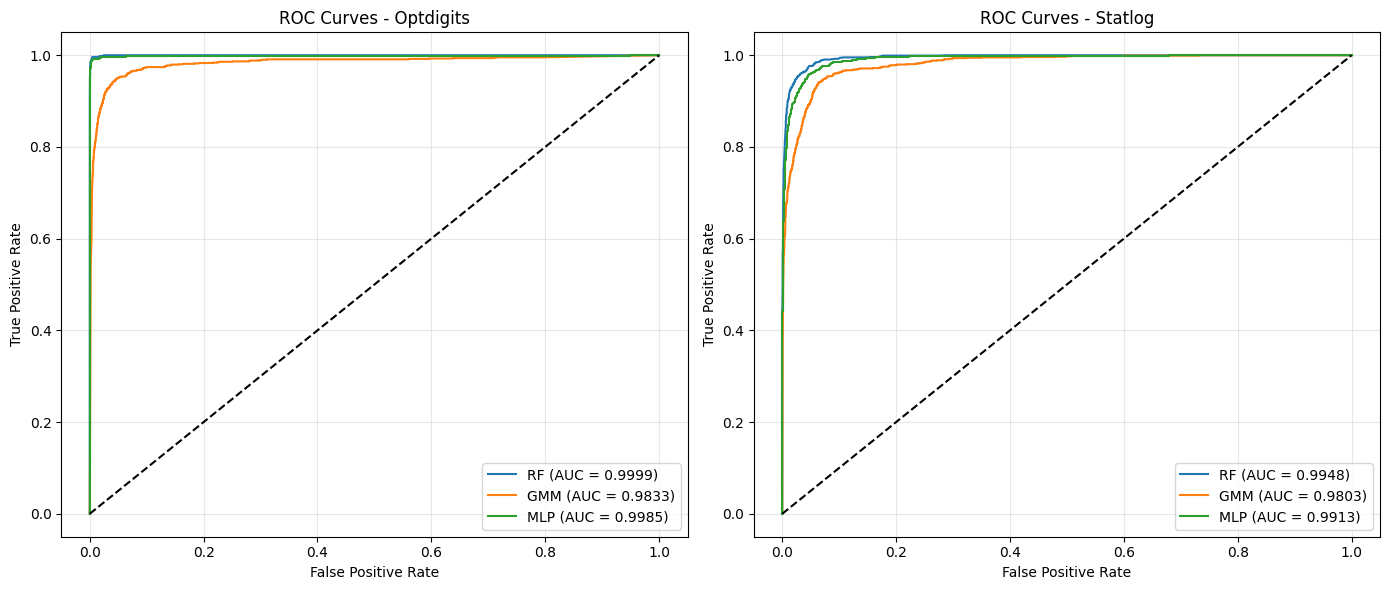

✅ ROC curves plotted and saved as roc_curves_all_models.png


In [ ]:
# ============================================================
# SECTION 5: ROC Curves for RF, GMM, and MLP
# ============================================================

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Helper 1: Get best GMM params safely
# ------------------------------------------------------------

def get_gmm_params(dataset_name):
    if dataset_name == "Optdigits" and "best_gmm_opt_params" in globals():
        return best_gmm_opt_params

    if dataset_name == "Statlog" and "best_gmm_sat_params" in globals():
        return best_gmm_sat_params

    if dataset_name == "Optdigits" and "best_opt" in globals():
        return {
            "covariance_type": best_opt[0],
            "n_components": best_opt[1]
        }

    if dataset_name == "Statlog" and "best_sat" in globals():
        return {
            "covariance_type": best_sat[0],
            "n_components": best_sat[1]
        }

    print(f"WARNING: Best GMM params for {dataset_name} not found. Using default: K=2, covariance_type='diag'")
    return {
        "n_components": 2,
        "covariance_type": "diag"
    }


# ------------------------------------------------------------
# Helper 2: Clean MLP params
# ------------------------------------------------------------

def clean_mlp_params(params):
    cleaned = {}

    valid_keys = MLPClassifier().get_params().keys()

    for k, v in params.items():

        # Fix your numeric learning_rate problem
        if k == "learning_rate":
            if isinstance(v, (int, float, np.integer, np.floating)):
                cleaned["learning_rate_init"] = float(v)
            else:
                cleaned["learning_rate"] = v
            continue

        # If your code used optimizer instead of solver
        if k == "optimizer":
            if str(v).lower() == "adam":
                cleaned["solver"] = "adam"
            elif str(v).lower() == "sgd":
                cleaned["solver"] = "sgd"
            else:
                cleaned["solver"] = "adam"
            continue

        # Remove unsupported or duplicate params
        if k in ["max_iter", "early_stopping", "random_state", "dropout", "epochs"]:
            continue

        # Keep only valid sklearn MLPClassifier params
        if k in valid_keys:
            cleaned[k] = v

    return cleaned


# ------------------------------------------------------------
# Helper 3: Clean RF params
# ------------------------------------------------------------

def clean_rf_params(params):
    cleaned = {
        k: v for k, v in params.items()
        if k not in ["random_state", "n_jobs"]
    }
    return cleaned


# ------------------------------------------------------------
# Prepare configs
# ------------------------------------------------------------

roc_configs = [
    {
        "name": "Optdigits",
        "X": datasets["Optdigits"]["X"],
        "y": datasets["Optdigits"]["y"],
        "folds": datasets["Optdigits"]["folds"],
        "rf_params": best_params_opt,
        "gmm_params": get_gmm_params("Optdigits"),
        "mlp_params": best_mlp_opt,
        "title": "ROC Curves - Optdigits"
    },
    {
        "name": "Statlog",
        "X": datasets["Statlog"]["X"],
        "y": datasets["Statlog"]["y"],
        "folds": datasets["Statlog"]["folds"],
        "rf_params": best_params_sat,
        "gmm_params": get_gmm_params("Statlog"),
        "mlp_params": best_mlp_sat,
        "title": "ROC Curves - Statlog"
    }
]


# ------------------------------------------------------------
# Plot ROC curves
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for cfg, ax in zip(roc_configs, axes):

    X = cfg["X"]
    y = cfg["y"]
    classes = np.unique(y)

    # Use the first stratified fold for ROC plotting
    train_idx, test_idx = cfg["folds"][0]

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Binarize labels for multiclass ROC
    y_bin = label_binarize(y_test, classes=classes)

    rf_params_clean = clean_rf_params(cfg["rf_params"])
    mlp_params_clean = clean_mlp_params(cfg["mlp_params"])

    models = [
        (
            "RF",
            RandomForestClassifier(
                **rf_params_clean,
                random_state=42,
                n_jobs=-1
            )
        ),
        (
            "GMM",
            GMMClassifier(
                **cfg["gmm_params"]
            )
        ),
        (
            "MLP",
            MLPClassifier(
                **mlp_params_clean,
                max_iter=500,
                early_stopping=True,
                random_state=42
            )
        )
    ]

    for clf_name, clf in models:

        clf.fit(X_train, y_train)

        y_prob = clf.predict_proba(X_test)

        # Micro-average ROC curve
        fpr, tpr, _ = roc_curve(y_bin.ravel(), y_prob.ravel())
        roc_auc = auc(fpr, tpr)

        ax.plot(fpr, tpr, label=f"{clf_name} (AUC = {roc_auc:.4f})")

    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(cfg["title"])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("roc_curves_all_models.png", dpi=150)
plt.show()

print("✅ ROC curves plotted and saved as roc_curves_all_models.png")

In [ ]:
# ============================================================
# SECTION 5: Final Comparative Evaluation Table
# Accuracy, Recall/Sensitivity, Specificity, F1, AUC-ROC,
# Training Time, Inference Time
# ============================================================

import time
import ast
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize


# ------------------------------------------------------------
# Helper: Specificity for multiclass classification
# Specificity is calculated one-vs-rest for each class,
# then averaged across classes.
# ------------------------------------------------------------

def multiclass_specificity(y_true, y_pred):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    specificities = []

    for i in range(len(labels)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        tn = cm.sum() - tp - fp - fn

        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificities.append(specificity)

    return np.mean(specificities)


# ------------------------------------------------------------
# Helper: Clean Random Forest parameters
# ------------------------------------------------------------

def clean_rf_params(params):
    return {
        k: v for k, v in params.items()
        if k not in ["random_state", "n_jobs"]
    }


# ------------------------------------------------------------
# Helper: Build GMM model from best row
# ------------------------------------------------------------

def build_gmm_from_best(best_row):
    if isinstance(best_row, pd.Series):
        best_row = best_row.to_dict()

    return GMMClassifier(
        n_components=int(best_row["K"]),
        covariance_type=best_row["covariance_type"],
        init_params=best_row["init"],
        random_state=42
    )


# ------------------------------------------------------------
# Helper: Build MLP model from best row
# ------------------------------------------------------------

def build_mlp_from_best(best_row):
    if isinstance(best_row, pd.Series):
        best_row = best_row.to_dict()

    hidden_layers = best_row["hidden_layers"]

    # In your output, hidden_layers appears like "(128, 64, 32)"
    if isinstance(hidden_layers, str):
        hidden_layers = ast.literal_eval(hidden_layers)

    return MLPClassifier(
        hidden_layer_sizes=hidden_layers,
        activation=best_row["activation"],
        solver=best_row["solver"],
        learning_rate_init=float(best_row["learning_rate"]),
        alpha=float(best_row["alpha"]),
        max_iter=int(best_row["max_iter"]),
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=42
    )


# ------------------------------------------------------------
# Helper: AUC-ROC for multiclass
# ------------------------------------------------------------

def safe_multiclass_auc(y_true, y_prob, classes):
    try:
        y_bin = label_binarize(y_true, classes=classes)

        # If binary case happens, label_binarize gives one column.
        # Your datasets are multiclass, but this keeps it safe.
        if y_bin.shape[1] == 1:
            return roc_auc_score(y_true, y_prob[:, 1])

        return roc_auc_score(
            y_bin,
            y_prob,
            average="macro",
            multi_class="ovr"
        )
    except Exception as e:
        print("AUC warning:", e)
        return np.nan


# ------------------------------------------------------------
# Main evaluation function
# ------------------------------------------------------------

def evaluate_model_cv(model_builder, X, y, folds, model_name, dataset_name):
    accs = []
    recalls = []
    specs = []
    f1s = []
    aucs = []
    train_times = []
    infer_times = []

    classes = np.unique(y)

    for fold_num, (train_idx, val_idx) in enumerate(folds, 1):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        model = model_builder()

        # Training time
        t0 = time.time()
        model.fit(X_train, y_train)
        train_times.append(time.time() - t0)

        # Inference time
        t1 = time.time()
        y_pred = model.predict(X_val)
        infer_times.append(time.time() - t1)

        # Metrics
        accs.append(accuracy_score(y_val, y_pred))
        recalls.append(recall_score(y_val, y_pred, average="macro", zero_division=0))
        specs.append(multiclass_specificity(y_val, y_pred))
        f1s.append(f1_score(y_val, y_pred, average="macro", zero_division=0))

        # AUC-ROC
        if hasattr(model, "predict_proba"):
            y_prob = model.predict_proba(X_val)
            aucs.append(safe_multiclass_auc(y_val, y_prob, classes))
        else:
            aucs.append(np.nan)

    return {
        "Dataset": dataset_name,
        "Model": model_name,

        "Accuracy Mean": np.mean(accs),
        "Accuracy Std": np.std(accs),

        "Recall/Sensitivity Mean": np.mean(recalls),
        "Recall/Sensitivity Std": np.std(recalls),

        "Specificity Mean": np.mean(specs),
        "Specificity Std": np.std(specs),

        "F1-score Mean": np.mean(f1s),
        "F1-score Std": np.std(f1s),

        "AUC-ROC Mean": np.nanmean(aucs),
        "AUC-ROC Std": np.nanstd(aucs),

        "Train Time Mean (s)": np.mean(train_times),
        "Train Time Std (s)": np.std(train_times),

        "Inference Time Mean (s)": np.mean(infer_times),
        "Inference Time Std (s)": np.std(infer_times)
    }


# ------------------------------------------------------------
# Build final evaluation configs
# ------------------------------------------------------------

evaluation_configs = [
    {
        "dataset_name": "Optdigits",
        "X": datasets["Optdigits"]["X"],
        "y": datasets["Optdigits"]["y"],
        "folds": datasets["Optdigits"]["folds"],
        "models": [
            (
                "Random Forest",
                lambda: RandomForestClassifier(
                    **clean_rf_params(best_params_opt),
                    random_state=42,
                    n_jobs=-1
                )
            ),
            (
                "GMM",
                lambda: build_gmm_from_best(best_gmm_opt)
            ),
            (
                "MLP",
                lambda: build_mlp_from_best(best_mlp_opt)
            )
        ]
    },
    {
        "dataset_name": "Statlog",
        "X": datasets["Statlog"]["X"],
        "y": datasets["Statlog"]["y"],
        "folds": datasets["Statlog"]["folds"],
        "models": [
            (
                "Random Forest",
                lambda: RandomForestClassifier(
                    **clean_rf_params(best_params_sat),
                    random_state=42,
                    n_jobs=-1
                )
            ),
            (
                "GMM",
                lambda: build_gmm_from_best(best_gmm_sat)
            ),
            (
                "MLP",
                lambda: build_mlp_from_best(best_mlp_sat)
            )
        ]
    }
]


# ------------------------------------------------------------
# Run final evaluation
# ------------------------------------------------------------

final_results = []

for cfg in evaluation_configs:
    print(f"\nEvaluating models on {cfg['dataset_name']}...")

    for model_name, model_builder in cfg["models"]:
        print(f"  Running {model_name}...")

        result = evaluate_model_cv(
            model_builder=model_builder,
            X=cfg["X"],
            y=cfg["y"],
            folds=cfg["folds"],
            model_name=model_name,
            dataset_name=cfg["dataset_name"]
        )

        final_results.append(result)


final_eval_df = pd.DataFrame(final_results)


# ------------------------------------------------------------
# Pretty table with mean ± std
# ------------------------------------------------------------

def mean_std_str(mean, std, decimals=4):
    return f"{mean:.{decimals}f} ± {std:.{decimals}f}"


final_comparison_table = pd.DataFrame({
    "Dataset": final_eval_df["Dataset"],
    "Model": final_eval_df["Model"],

    "Accuracy": [
        mean_std_str(m, s)
        for m, s in zip(final_eval_df["Accuracy Mean"], final_eval_df["Accuracy Std"])
    ],

    "Recall/Sensitivity": [
        mean_std_str(m, s)
        for m, s in zip(final_eval_df["Recall/Sensitivity Mean"], final_eval_df["Recall/Sensitivity Std"])
    ],

    "Specificity": [
        mean_std_str(m, s)
        for m, s in zip(final_eval_df["Specificity Mean"], final_eval_df["Specificity Std"])
    ],

    "F1-score": [
        mean_std_str(m, s)
        for m, s in zip(final_eval_df["F1-score Mean"], final_eval_df["F1-score Std"])
    ],

    "AUC-ROC": [
        mean_std_str(m, s)
        for m, s in zip(final_eval_df["AUC-ROC Mean"], final_eval_df["AUC-ROC Std"])
    ],

    "Train Time (s)": [
        mean_std_str(m, s, decimals=3)
        for m, s in zip(final_eval_df["Train Time Mean (s)"], final_eval_df["Train Time Std (s)"])
    ],

    "Inference Time (s)": [
        mean_std_str(m, s, decimals=4)
        for m, s in zip(final_eval_df["Inference Time Mean (s)"], final_eval_df["Inference Time Std (s)"])
    ],
})


print("\n" + "="*90)
print("FINAL COMPARATIVE EVALUATION TABLE")
print("="*90)

display(final_comparison_table)


# ------------------------------------------------------------
# Print separate tables per dataset, as required
# ------------------------------------------------------------

for ds_name in final_comparison_table["Dataset"].unique():
    print("\n" + "="*90)
    print(f"FINAL COMPARISON TABLE — {ds_name}")
    print("="*90)

    display(final_comparison_table[final_comparison_table["Dataset"] == ds_name])


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

final_eval_df.to_csv("final_evaluation_raw_metrics.csv", index=False)
final_comparison_table.to_csv("final_comparison_table.csv", index=False)

print("\n✅ Final evaluation complete.")
print("Saved files:")
print(" - final_evaluation_raw_metrics.csv")
print(" - final_comparison_table.csv")


Evaluating models on Optdigits...
  Running Random Forest...
  Running GMM...
  Running MLP...

Evaluating models on Statlog...
  Running Random Forest...
  Running GMM...
  Running MLP...

FINAL COMPARATIVE EVALUATION TABLE


,Dataset,Model,Accuracy,Recall/Sensitivity,Specificity,F1-score,AUC-ROC,Train Time (s),Inference Time (s)
0,Optdigits,Random Forest,0.9836 ± 0.0033,0.9836 ± 0.0033,0.9982 ± 0.0004,0.9836 ± 0.0033,0.9997 ± 0.0001,3.996 ± 0.657,0.1713 ± 0.0011
1,Optdigits,GMM,0.9601 ± 0.0054,0.9603 ± 0.0053,0.9956 ± 0.0006,0.9606 ± 0.0052,0.9926 ± 0.0021,3.337 ± 0.796,0.1142 ± 0.0366
2,Optdigits,MLP,0.9813 ± 0.0027,0.9813 ± 0.0027,0.9979 ± 0.0003,0.9813 ± 0.0027,0.9993 ± 0.0004,1.631 ± 0.952,0.0036 ± 0.0001
3,Statlog,Random Forest,0.9200 ± 0.0047,0.8940 ± 0.0044,0.9835 ± 0.0009,0.9016 ± 0.0055,0.9905 ± 0.0007,5.400 ± 0.643,0.1716 ± 0.0062
4,Statlog,GMM,0.8813 ± 0.0084,0.8495 ± 0.0107,0.9758 ± 0.0017,0.8498 ± 0.0109,0.9757 ± 0.0034,4.917 ± 0.562,0.1137 ± 0.1235
5,Statlog,MLP,0.9049 ± 0.0068,0.8828 ± 0.0103,0.9807 ± 0.0014,0.8852 ± 0.0088,0.9881 ± 0.0012,8.303 ± 2.319,0.0246 ± 0.0132



FINAL COMPARISON TABLE — Optdigits


,Dataset,Model,Accuracy,Recall/Sensitivity,Specificity,F1-score,AUC-ROC,Train Time (s),Inference Time (s)
0,Optdigits,Random Forest,0.9836 ± 0.0033,0.9836 ± 0.0033,0.9982 ± 0.0004,0.9836 ± 0.0033,0.9997 ± 0.0001,3.996 ± 0.657,0.1713 ± 0.0011
1,Optdigits,GMM,0.9601 ± 0.0054,0.9603 ± 0.0053,0.9956 ± 0.0006,0.9606 ± 0.0052,0.9926 ± 0.0021,3.337 ± 0.796,0.1142 ± 0.0366
2,Optdigits,MLP,0.9813 ± 0.0027,0.9813 ± 0.0027,0.9979 ± 0.0003,0.9813 ± 0.0027,0.9993 ± 0.0004,1.631 ± 0.952,0.0036 ± 0.0001



FINAL COMPARISON TABLE — Statlog


,Dataset,Model,Accuracy,Recall/Sensitivity,Specificity,F1-score,AUC-ROC,Train Time (s),Inference Time (s)
3,Statlog,Random Forest,0.9200 ± 0.0047,0.8940 ± 0.0044,0.9835 ± 0.0009,0.9016 ± 0.0055,0.9905 ± 0.0007,5.400 ± 0.643,0.1716 ± 0.0062
4,Statlog,GMM,0.8813 ± 0.0084,0.8495 ± 0.0107,0.9758 ± 0.0017,0.8498 ± 0.0109,0.9757 ± 0.0034,4.917 ± 0.562,0.1137 ± 0.1235
5,Statlog,MLP,0.9049 ± 0.0068,0.8828 ± 0.0103,0.9807 ± 0.0014,0.8852 ± 0.0088,0.9881 ± 0.0012,8.303 ± 2.319,0.0246 ± 0.0132



✅ Final evaluation complete.
Saved files:
 - final_evaluation_raw_metrics.csv
 - final_comparison_table.csv
